In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
results = pd.read_csv("/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/training_output/new_MC/larger_MC/dynedge_dbang_decay_length/esults.csv")
results_1m = pd.read_csv("/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/training_output/new_MC/1m_min/dynedge_dbang_decay_length/esults.csv")

In [4]:
results.head()

,Unnamed: 0,dbang_decay_length_pred,dbang_decay_length,pid,energy,event_weight,azimuth,zenith,event_no
0,0,1.260428,80.592375,16.0,49.411306,6.395898e-15,2.342150,2.220942,0.0
1,1,1.129447,19.179646,16.0,18.538009,1.698418e-14,3.966716,2.226325,1.0
2,2,1.096222,12.140926,16.0,147.594729,4.059710e-17,1.554518,1.927149,2.0
3,3,0.836919,2.125797,16.0,513.538722,1.443288e-20,4.164540,1.822650,3.0
4,4,1.223313,134.429503,16.0,4720.280472,2.016766e-21,1.095889,2.803243,4.0


Text(0.5, 1.0, 'Learning rate 1e-2')

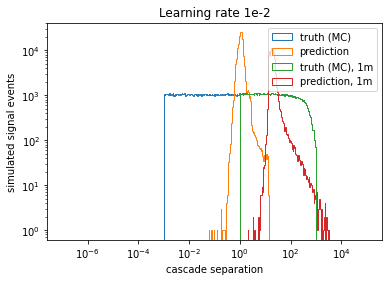

In [3]:
bins = np.logspace(-7, 5, 500)

plt.hist(results['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC)")
plt.hist(results['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction")

plt.hist(results_1m['dbang_decay_length'], histtype="step", bins=bins, label="truth (MC), 1m")
plt.hist(results_1m['dbang_decay_length_pred'], histtype="step", bins=bins, label="prediction, 1m")


plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('cascade separation')
plt.ylabel('simulated signal events')
# plt.xlabel("Energy(GeV)")
plt.title("Learning rate 1e-2")

Two figures to work towards: 
Classification score for signal vs background


Text(0.5, 1.0, 'Cascade separation, HNL only')

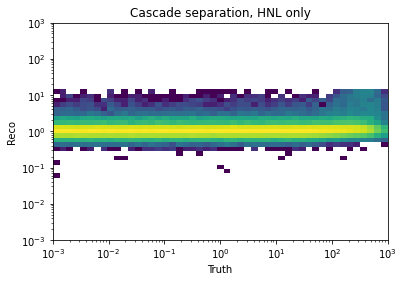

In [5]:
from matplotlib import colors

bins = np.logspace(-3, 3, 50)
plt.hist2d(results['dbang_decay_length'],results['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only")

# plt.colorbar()

Text(0.5, 1.0, 'Cascade separation, HNL only, 1m min separation, true energy>100GeV')

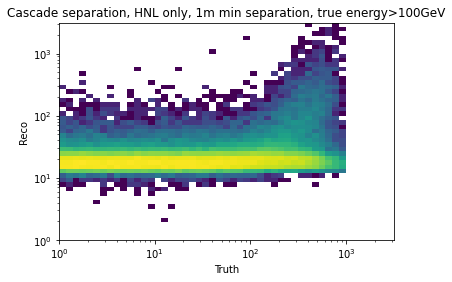

In [6]:
bins = np.logspace(0, 3.5, 50)
energy_mask = results_1m['energy']>00.0
plt.hist2d(results_1m[energy_mask]['dbang_decay_length'],results_1m[energy_mask]['dbang_decay_length_pred'], bins=bins, norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Truth")
plt.ylabel("Reco")
plt.title("Cascade separation, HNL only, 1m min separation")

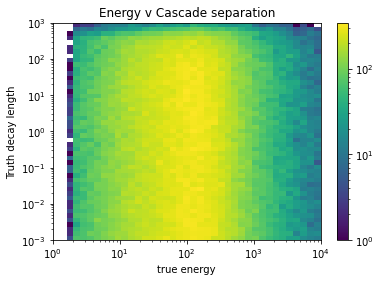

In [8]:
ybins = np.logspace(-3, 3, 50)
xbins = np.logspace(0, 4, 40)
plt.hist2d(results['energy'], results['dbang_decay_length'], bins=[xbins, ybins], norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.ylabel("Truth decay length")
plt.xlabel("true energy")
plt.title("Energy v Cascade separation")

plt.colorbar()

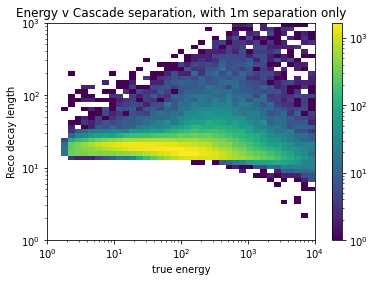

In [23]:
ybins = np.logspace(0, 3, 50)
xbins = np.logspace(0, 4, 40)
plt.hist2d(results_1m['energy'], results_1m['dbang_decay_length_pred'], bins=[xbins, ybins], norm=colors.LogNorm())

plt.xscale('log')
plt.yscale('log')

plt.ylabel("Reco decay length")
plt.xlabel("true energy")
plt.title("Energy v Cascade separation, with 1m separation only")

plt.colorbar()

### Hypothesis:
What if we only train on higher energy events? It looks like we may have a lot more potential over 100 GeV. That being said, I think it's time to move one to a classifier for now.

That is, after adding layers as Carlos suggested.